# Lab 04-01 · Mechanics Essentials for EE

Companion to chapter [04-01](../../chapters/04-01-mechanics-essentials.md). Handout: [README.md](README.md). The ngspice netlist [msd_analog.cir](msd_analog.cir) simulates the RLC twin of Example 04-01.5; run it with `python tools/run_spice.py 04-01` from the repository root.

Each part integrates Newton's law numerically and checks the chapter's formulas. Cells marked **🔮 Predict** ask for a prediction *before* running. The seed is fixed.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
rng = np.random.default_rng(2026)
g, kB = 9.80665, 1.380649e-23

## Part 1 — Integrating Newton's law

An undamped 10 g mass on a 1000 N/m spring ($f_0$ = 50.33 Hz) starts at $x$ = 1 cm, at rest. Integrate $m\ddot x = -k_sx$ for 100 periods three ways: forward Euler, semi-implicit (symplectic) Euler, and a high-accuracy solver. Track the total energy, which should stay at $\tfrac12k_sA^2$ = 50 mJ.

**🔮 Predict:** with a step of 1/200 of a period, does forward Euler's energy drift up or down? By roughly how much after 100 periods?

In [2]:
m, ks = 0.01, 1000.0
w0 = math.sqrt(ks / m)
T0 = 2 * math.pi / w0
dt = T0 / 200
n = 200 * 100
E = lambda x, v: 0.5 * m * v**2 + 0.5 * ks * x**2

x, v = 0.01, 0.0                       # forward Euler
for _ in range(n):
    x, v = x + v * dt, v - ks / m * x * dt
E_fe = E(x, v)
x, v = 0.01, 0.0                       # semi-implicit Euler: update v first, then x with the new v
for _ in range(n):
    v = v - ks / m * x * dt
    x = x + v * dt
E_si = E(x, v)
sol = solve_ivp(lambda t, y: [y[1], -ks / m * y[0]], (0, 100 * T0), [0.01, 0.0], rtol=1e-10, atol=1e-13)
E_rk = E(sol.y[0, -1], sol.y[1, -1])
print(f"initial energy 50.000 mJ")
print(f"forward Euler      {E_fe * 1e3:.4g} mJ   (theory: 50 mJ x (1 + (w0 dt)^2)^n = {50 * (1 + (w0 * dt)**2)**n:.4g} mJ)")
print(f"semi-implicit Euler {E_si * 1e3:8.3f} mJ")
print(f"adaptive RK45       {E_rk * 1e3:8.3f} mJ")

initial energy 50.000 mJ
forward Euler      1.851e+10 mJ   (theory: 50 mJ x (1 + (w0 dt)^2)^n = 1.851e+10 mJ)
semi-implicit Euler   49.959 mJ
adaptive RK45         50.000 mJ


Forward Euler pumps energy in at every step (each step multiplies the energy by $1 + (\omega_0\Delta t)^2$), so a long simulation "explodes". The semi-implicit update keeps the energy bounded, which is why it is the workhorse of mechanics and circuit simulators' companions alike ([02-10](../../../02-complex-numbers-des-and-linear-algebra/chapters/02-10-numerical-methods-for-engineers.md)).

## Part 2 — Energy sloshing and the energy definition of Q

Add the damper of Example 04-01.5 ($b$ = 0.4 N·s/m, Q = 7.906) and compute the energy lost in each cycle.

**🔮 Predict:** what fraction of its energy does the oscillator lose per cycle?

Q = 7.9057; fraction of energy lost per cycle: 0.5490, 0.5490, 0.5490, 0.5490, 0.5490
2*pi/Q = 0.7948  (light-damping estimate);  exact 1 - exp(-2 alpha Td) = 0.5490


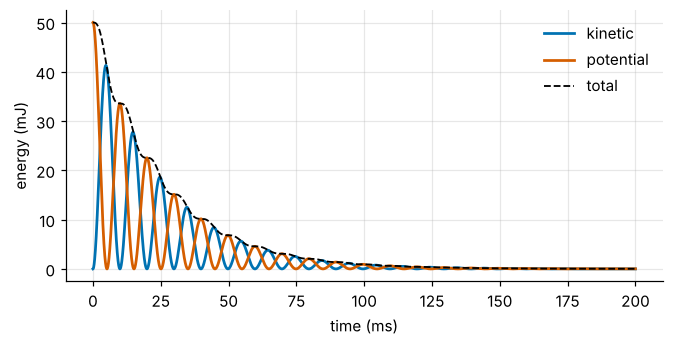

In [3]:
b = 0.4
Q = m * w0 / b
sol = solve_ivp(lambda t, y: [y[1], (-ks * y[0] - b * y[1]) / m], (0, 0.2), [0.01, 0.0],
                rtol=1e-10, atol=1e-13, dense_output=True)
t = np.linspace(0, 0.2, 20001)
x, v = sol.sol(t)
Et = 0.5 * m * v**2 + 0.5 * ks * x**2
wd = math.sqrt(w0**2 - (b / (2 * m))**2)
Td = 2 * math.pi / wd
idx = [int(round(k * Td / (t[1] - t[0]))) for k in range(6)]
frac = [(Et[idx[k]] - Et[idx[k + 1]]) / Et[idx[k]] for k in range(5)]
print(f"Q = {Q:.4f}; fraction of energy lost per cycle: {', '.join(f'{f:.4f}' for f in frac)}")
print(f"2*pi/Q = {2 * math.pi / Q:.4f}  (light-damping estimate);  exact 1 - exp(-2 alpha Td) = {1 - math.exp(-b / m * Td):.4f}")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(t * 1e3, 0.5 * m * v**2 * 1e3, label="kinetic")
ax.plot(t * 1e3, 0.5 * ks * x**2 * 1e3, label="potential")
ax.plot(t * 1e3, Et * 1e3, "k--", lw=1.2, label="total")
ax.set_xlabel("time (ms)"); ax.set_ylabel("energy (mJ)"); ax.legend(); plt.show()

At Q = 7.906 the oscillator loses about 55% of its energy per cycle by the exact formula $1 - e^{-2\alpha T_d}$; the light-damping estimate $2\pi/Q$ = 0.79 overshoots, because the energy definition of Q is exact only as Q grows large. Raise Q to 100 in the cell above and the two agree closely.

## Part 3 — Two ways to measure Q

Measure Q of the same oscillator (a) from its ring-down, using the logarithmic decrement $\delta = \ln(x_k/x_{k+1})$ between successive peaks one period apart, with $Q \approx \pi/\delta$ for light damping (exactly $Q = \sqrt{4\pi^2 + \delta^2}/(2\delta)$); and (b) from the half-power width of the velocity response in a frequency sweep.

**🔮 Predict:** will the two methods agree?

In [4]:
pk, _ = find_peaks(x)
delta = np.mean(np.log(x[pk[:-1]] / x[pk[1:]]))
Q_ring = math.sqrt(4 * math.pi**2 + delta**2) / (2 * delta)
f = np.linspace(30, 80, 200001)
w = 2 * math.pi * f
vel = w / np.sqrt((ks - m * w**2)**2 + (b * w)**2)          # |velocity| per newton of force
rel = vel / vel.max()
above = f[rel >= 1 / math.sqrt(2)]
Q_bw = (w0 / (2 * math.pi)) / (above[-1] - above[0])
print(f"log decrement {delta:.4f} -> Q = {Q_ring:.4f} (light-damping pi/delta = {math.pi / delta:.4f});  half-power width {above[-1] - above[0]:.4f} Hz -> Q = {Q_bw:.4f};  m w0/b = {Q:.4f}")

log decrement 0.3982 -> Q = 7.9057 (light-damping pi/delta = 7.8899);  half-power width 6.3660 Hz -> Q = 7.9059;  m w0/b = 7.9057


Both match $m\omega_0/b$. Ring-down is the usual measurement for high-Q resonators (a crystal or a MEMS gyroscope rings for thousands of cycles), and the frequency sweep for low-Q systems.

## Part 4 — The accelerometer's sensitivity–bandwidth tradeoff

Compute the deflection per *g* and the −3 dB bandwidth of a proof-mass accelerometer for several resonant frequencies and values of Q.

**🔮 Predict:** at $Q = 1/\sqrt2$, how much deflection does a 4 kHz design give per *g*? What happens to the bandwidth at Q = 0.5 and at Q = 2?

In [5]:
def resp(f, f0, Q):
    w, w0_ = 2 * np.pi * f, 2 * np.pi * f0
    return 1 / np.sqrt((w0_**2 - w**2)**2 + (w * w0_ / Q)**2)
ff = np.logspace(1, 5, 400001)
print(" f0 (kHz)   Q     x per g (nm)   -3 dB bandwidth (kHz)   peak/DC")
for f0 in (1e3, 4e3, 16e3):
    for Q_ in (0.5, 1 / math.sqrt(2), 2.0):
        H = resp(ff, f0, Q_)
        H0 = resp(0.0, f0, Q_)
        bw = ff[np.nonzero(H >= H0 / math.sqrt(2))[0][-1]]
        print(f"{f0 / 1e3:7.0f}   {Q_:5.3f}   {g * H0 * 1e9:10.4f}     {bw / 1e3:10.4f}             {H.max() / H0:6.3f}")

 f0 (kHz)   Q     x per g (nm)   -3 dB bandwidth (kHz)   peak/DC
      1   0.500     248.4053         0.6436              1.000
      1   0.707     248.4053         1.0000              1.000
      1   2.000     248.4053         1.4845              2.066
      4   0.500      15.5253         2.5744              1.000
      4   0.707      15.5253         3.9999              1.000
      4   2.000      15.5253         5.9380              2.066
     16   0.500       0.9703        10.2975              1.000
     16   0.707       0.9703        15.9996              1.000
     16   2.000       0.9703        23.7520              2.066


The deflection depends only on $f_0$ (as $1/f_0^2$); Q trades flatness against bandwidth. At $Q = 1/\sqrt2$ the bandwidth equals $f_0$ with no peaking; Q = 2 stretches the bandwidth but adds a 2.07-fold resonant peak.

## Part 5 — Brownian motion of a proof mass

Simulate Example 04-01.6's proof mass (5 µg, 4 kHz, Q = 0.707) at 300 K, driven only by the thermal force of one-sided density $4kTb$, for an ensemble of 1000 masses. In discrete time a white force of one-sided density $G_F$ has variance $G_F/(2\Delta t)$ per step.

**🔮 Predict:** the rms displacement after the masses reach equilibrium.

In [6]:
m6, f06, Q6, T = 5e-9, 4000.0, 1 / math.sqrt(2), 300.0
w06 = 2 * math.pi * f06
k6, b6 = m6 * w06**2, m6 * w06 / Q6
dt = 1e-7
paths, steps = 1000, 60000                     # 6 ms, about 24 periods
sigF = math.sqrt(4 * kB * T * b6 / (2 * dt))
x = np.zeros(paths); v = np.zeros(paths)
acc = []
for i in range(steps):
    F = sigF * rng.standard_normal(paths)
    v += (-k6 * x - b6 * v + F) / m6 * dt
    x += v * dt
    if i >= steps // 2:
        acc.append(np.mean(x**2))
xrms = math.sqrt(np.mean(acc))
print(f"simulated rms displacement {xrms * 1e12:.2f} pm;  equipartition sqrt(kT/k_s) = {math.sqrt(kB * T / k6) * 1e12:.2f} pm")

simulated rms displacement 36.12 pm;  equipartition sqrt(kT/k_s) = 36.21 pm


The ensemble settles at the equipartition value within the simulation's statistical scatter: the spring holds $\tfrac12kT$ of energy on average, whatever the mass or damping. The same physics gave $kT/C$ on a capacitor in Lab 03-06.

## Part 6 — A drop-test shock seen by the proof mass

Apply Example 04-01.3's half-sine pulse (peak 42,600 m/s², 0.2 ms) to the accelerometer and find the proof mass's peak deflection.

**🔮 Predict:** is the peak deflection larger or smaller than the quasi-static value $a_{\text{pk}}/\omega_0^2$ = 67.44 µm? Compare it with the micrometer-scale gaps between a MEMS proof mass and its electrodes.

In [7]:
apk, dur = math.pi / 2 * math.sqrt(2 * g * 1.5) / 0.2e-3, 0.2e-3
a_in = lambda t: apk * math.sin(math.pi * t / dur) if t < dur else 0.0
sol = solve_ivp(lambda t, y: [y[1], -a_in(t) - b6 / m6 * y[1] - k6 / m6 * y[0]], (0, 1.5e-3), [0.0, 0.0],
                max_step=1e-7, rtol=1e-9, atol=1e-16)
xpk = np.max(np.abs(sol.y[0]))
print(f"peak a = {apk:.0f} m/s^2 ({apk / g:.0f} g);  quasi-static deflection {apk / w06**2 * 1e6:.2f} um;  simulated peak {xpk * 1e6:.2f} um")

peak a = 42600 m/s^2 (4344 g);  quasi-static deflection 67.44 um;  simulated peak 60.31 um


The pulse lasts less than one natural period (0.25 ms), so the mass cannot follow it quasi-statically, and with $Q = 0.707$ there is little overshoot: the peak stays somewhat below the quasi-static value. But both are tens of *micrometers*, far more than the micrometer-scale gaps around a MEMS proof mass. In a real device the mass slams into mechanical stops long before that, and the design question becomes whether the stops, springs and surfaces survive the impact and release afterward (no stiction). That is what a datasheet's shock-survival rating certifies (§9).

## Your turn

1. In Part 1, halve the step size. By what factor does forward Euler's energy error after 100 periods shrink? Explain from the per-step factor.
2. In Part 5, raise Q to 50 (lower damping) with the same mass and $f_0$. Does the rms displacement change? Does the noise *density* at low frequency change? Explain both answers from the chapter's formulas.